# AI 5 · Which model is best, and is it best all the time?
In notebooks 1-3 every model was tested on **one** period of 60 days. One period can be luck.

Here we do a **walk-forward test**: we cut the history into 60-day windows and test each one,
training only on the days **before** it. That is exactly what would happen in real life.

```
window 1:  [train ......... ][test 60]
window 2:  [train .................... ][test 60]
window 3:  [train ............................... ][test 60]
...
```
Models: baseline "tomorrow = today", Random Forest (notebook 1), neural network (notebook 2), TimesFM (notebook 3).
Runs in about 30 seconds.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import torch
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from torch import nn
from transformers import TimesFm2_5ModelForPrediction

SYMBOL = "AAPL"          # try "MSFT", "AMZN", "GOOGL"
WINDOW = 60              # test days per window
FIRST_TRAIN = 500        # about 2 years of training before the first window

/Users/bertram/Projects/github.com/b3rtram/uas_ml/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data and features: the same as in notebooks 1 and 2

In [2]:
prices = pd.read_parquet("../lecture03_datascience/sample/prices_sample.parquet")
close = prices[prices["symbol"] == SYMBOL].set_index("date")["close"]

ret = close.pct_change() * 100
X = pd.concat({f"lag{i}": ret.shift(i) for i in range(10)}, axis=1)
data = pd.concat([X, ret.shift(-1).rename("target")], axis=1).dropna()

# windows counted back from the end: the last window = the 60 test days of notebooks 1-3
starts = list(range(len(data) - WINDOW, FIRST_TRAIN - 1, -WINDOW))[::-1]
print(len(data), "days ->", len(starts), "test windows")

1246 days -> 12 test windows


## The three models as small functions: train on `train`, predict returns for `test`

In [3]:
def random_forest(train, test):
    model = RandomForestRegressor(n_estimators=200, min_samples_leaf=20, random_state=42)
    model.fit(train.drop(columns="target"), train["target"])
    return model.predict(test.drop(columns="target"))


def neural_net(train, test):
    torch.manual_seed(42)
    net = nn.Sequential(nn.Linear(10, 32), nn.ReLU(), nn.Linear(32, 1))
    optimizer = torch.optim.Adam(net.parameters(), lr=0.001)
    X_train = torch.tensor(train.drop(columns="target").values, dtype=torch.float32)
    y_train = torch.tensor(train[["target"]].values, dtype=torch.float32)
    for epoch in range(300):
        optimizer.zero_grad()
        loss = nn.MSELoss()(net(X_train), y_train)
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        return net(torch.tensor(test.drop(columns="target").values, dtype=torch.float32)).squeeze().numpy()


timesfm = TimesFm2_5ModelForPrediction.from_pretrained("google/timesfm-2.5-200m-transformers")

def times_fm(train, test):
    # no training: for each test day give TimesFM the last 512 prices up to that day
    histories = []
    for day in test.index:
        pos = close.index.get_loc(day)
        histories.append(torch.tensor(close.values[max(0, pos - 511) : pos + 1], dtype=torch.float32))
    with torch.no_grad():
        price_tomorrow = timesfm(past_values=histories, forecast_context_len=512).mean_predictions[:, 0].numpy()
    return (price_tomorrow / close.loc[test.index].values - 1) * 100   # price -> return in %

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 272/272 [00:00<00:00, 7701.22it/s]

## Walk forward: train, test, move on by 60 days

In [4]:
MODELS = {"Random Forest": random_forest, "Neural net": neural_net, "TimesFM": times_fm}

rows = []
for start in starts:
    train, test = data.iloc[:start], data.iloc[start : start + WINDOW]
    today = close.loc[test.index]
    tomorrow = close.shift(-1).loc[test.index]

    row = {"window start": test.index[0], "baseline": mean_absolute_error(tomorrow, today)}
    for name, predict in MODELS.items():
        pred = predict(train, test)
        row[name] = mean_absolute_error(tomorrow, today * (1 + pred / 100))
    rows.append(row)

result = pd.DataFrame(rows).set_index("window start")
result.round(2)

,baseline,Random Forest,Neural net,TimesFM
window start,,,,
2022-04-01,3.12,3.24,3.23,3.20
2022-06-29,2.23,2.39,2.63,2.29
2022-09-23,2.77,2.82,2.93,2.78
2022-12-19,1.92,2.04,2.03,1.88
2023-03-17,1.46,1.54,1.60,1.48
2023-06-13,1.79,1.78,1.91,1.81
2023-09-08,1.55,1.51,1.63,1.56
2023-12-04,1.59,1.60,1.76,1.62
2024-03-01,2.04,2.05,2.06,2.11


## MAE over time
All lines move up and down **together**: in calm months every model is good, in hectic months every model is bad.
The level of the error depends on the market, not on the model.

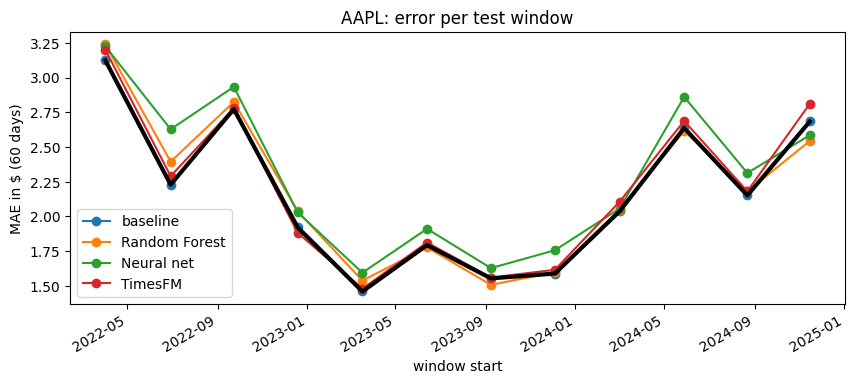

In [5]:
ax = result.plot(marker="o", figsize=(10, 4), ylabel=f"MAE in $ ({WINDOW} days)",
                 title=f"{SYMBOL}: error per test window")
result["baseline"].plot(ax=ax, color="black", lw=3, label="_");

## Better or worse than the baseline?
Divide by the baseline error: **below 0 % = better than "tomorrow = today"**, above 0 % = worse.

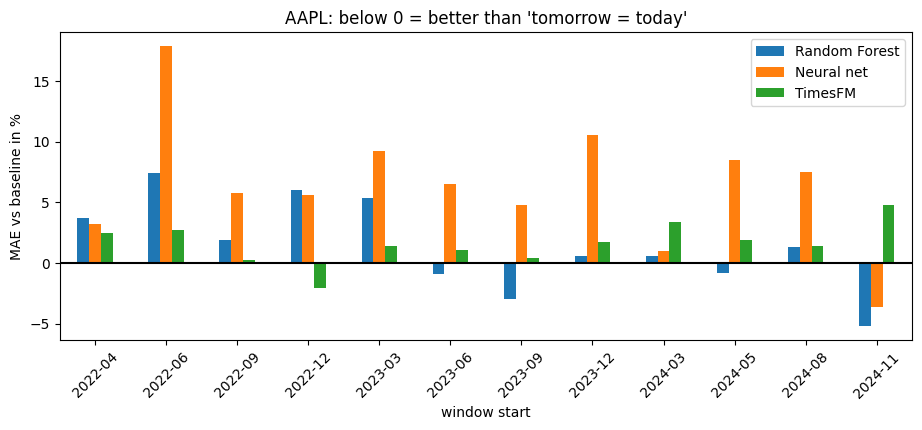

In [6]:
vs_baseline = (result[list(MODELS)].div(result["baseline"], axis=0) - 1) * 100

ax = vs_baseline.plot.bar(figsize=(11, 4), ylabel="MAE vs baseline in %",
                          title=f"{SYMBOL}: below 0 = better than 'tomorrow = today'")
ax.axhline(0, color="black")
ax.set_xticklabels([d.strftime("%Y-%m") for d in vs_baseline.index], rotation=45);

## Summary

In [7]:
summary = pd.DataFrame({
    "mean MAE ($)": result[list(MODELS)].mean(),
    "vs baseline (%)": vs_baseline.mean(),
    "windows won": (vs_baseline < 0).sum().astype(str) + f" / {len(result)}",
})
print(f"baseline mean MAE: {result['baseline'].mean():.2f} $")
summary.round(2)

baseline mean MAE: 2.16 $


,mean MAE ($),vs baseline (%),windows won
Random Forest,2.19,1.42,4 / 12
Neural net,2.29,6.41,1 / 12
TimesFM,2.20,1.61,1 / 12


## Takeaway (AAPL, 12 windows from 2022-04 to 2025-02)
| | mean MAE | vs baseline | windows won |
|---|---|---|---|
| baseline "tomorrow = today" | 2.16 $ | | |
| Random Forest | 2.19 $ | +1.4 % | 4 / 12 |
| Neural net | 2.29 $ | +6.4 % | 1 / 12 |
| TimesFM | 2.20 $ | +1.6 % | 1 / 12 |

- **No model beats the baseline over time.** The last window (2024-11) is the test period of notebooks 1-3: there the forest looked good. Over all windows that was luck.
- The neural network is the worst: with only ~1,000 rows it most likely fits noise (overfitting).
- Rule: **evaluate over many periods**, not one test set, before trusting a model. In the Stock App this is what *Monitoring* (chapter 06) does after deployment.